# Preprosesing data

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import os
import tensorflow as tf
from sklearn.preprocessing import OrdinalEncoder
import lightgbm as lgb
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
print("GPU Details:", tf.config.experimental.list_physical_devices('GPU'))

Num GPUs Available: 1
GPU Details: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Import data cần xử lý vào

In [ ]:
path = "../data"

calendar = pd.read_csv(os.path.join(path, "calendar.csv"))
prices = pd.read_csv(os.path.join(path, "sell_prices.csv"))
sales = pd.read_csv(os.path.join(path, "sales_train_evaluation.csv"))

In [ ]:


def prep_calendar(df):
    df = df.drop(["weekday", "event_type_1", "event_type_2"], axis=1)
    df = df.assign(d = df.d.str[2:].astype(int))
    to_ordinal = ["event_name_1", "event_name_2"] 
    df[to_ordinal] = df[to_ordinal].fillna("1")
    df[to_ordinal] = OrdinalEncoder(dtype="int").fit_transform(df[to_ordinal]) + 1
    to_int8 = ["wday", "month", "snap_CA", "snap_TX", "snap_WI"] + to_ordinal
    df[to_int8] = df[to_int8].astype("int8")
    
    return df

calendar = prep_calendar(calendar)
calendar.head()

In [4]:
def downcast(df):
    cols = df.dtypes.index.tolist()
    types = df.dtypes.values.tolist()
    
    for i, t in enumerate(types):
        col = cols[i]
        if 'int' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)

        elif 'float' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            # ⚠️ Không dùng float16 vì không lưu được trong Parquet
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)
        elif str(t) == 'object':
            if col == 'date':
                df[col] = pd.to_datetime(df[col], format='%Y-%m-%d')
            else:
                df[col] = df[col].astype('category')
    
    return df

In [5]:
# # Calculate memory usage before running the function
# memory_before = {
#     'calendar': calendar.memory_usage(deep=True).sum(),
#     'sales': sales.memory_usage(deep=True).sum(),
#     'prices': prices.memory_usage(deep=True).sum()
# }

# sales = downcast(sales)
# prices = downcast(prices)
# calendar = downcast(calendar)

# memory_after = {
#     'calendar': calendar.memory_usage(deep=True).sum(),
#     'sales': sales.memory_usage(deep=True).sum(),
#     'prices': prices.memory_usage(deep=True).sum()
# }

In [6]:
# def plot_memory_comparison(memory_before, memory_after):
#     """
#     Vẽ biểu đồ so sánh bộ nhớ sử dụng trước và sau khi tối ưu hóa.
    
#     Parameters:
#     -----------
#     memory_before : dict
#         Dictionary chứa bộ nhớ sử dụng trước khi tối ưu hóa.
#     memory_after : dict
#         Dictionary chứa bộ nhớ sử dụng sau khi tối ưu hóa.
#     """
    
#     # Lấy tên của các DataFrame
#     df_names = list(memory_before.keys())
    
#     # Tính toán giá trị bộ nhớ ở MB
#     before_mb = [memory_before[name] / (1024 * 1024) for name in df_names]
#     after_mb = [memory_after[name] / (1024 * 1024) for name in df_names]
    
#     # Tính phần trăm giảm bộ nhớ
#     reduction_pct = [(memory_before[name] - memory_after[name]) / memory_before[name] * 100 for name in df_names]
    
#     # Thiết lập vị trí của các cột
#     x = np.arange(len(df_names))
#     width = 0.35
    
#     # Tạo biểu đồ
#     fig, ax = plt.subplots(figsize=(12, 7))
    
#     # Vẽ cột
#     rects1 = ax.bar(x - width/2, before_mb, width, label='Trước khi downcast', color='#5DA5DA')
#     rects2 = ax.bar(x + width/2, after_mb, width, label='Sau khi downcast', color='#60BD68')
    
#     # Thêm nhãn, tiêu đề và các thông tin khác
#     ax.set_xlabel('DataFrame', fontsize=12)
#     ax.set_ylabel('Bộ nhớ sử dụng (MB)', fontsize=12)
#     ax.set_title('So sánh bộ nhớ sử dụng trước và sau khi áp dụng downcast', fontsize=14)
#     ax.set_xticks(x)
#     ax.set_xticklabels(df_names)
#     ax.legend()
    
#     # Thêm giá trị lên mỗi cột
#     def add_labels(rects):
#         for rect in rects:
#             height = rect.get_height()
#             ax.annotate(f'{height:.2f} MB',
#                          xy=(rect.get_x() + rect.get_width() / 2, height),
#                          xytext=(0, 3),  # 3 points vertical offset
#                          textcoords="offset points",
#                          ha='center', va='bottom')
    
#     add_labels(rects1)
#     add_labels(rects2)
    
#     # Thêm phần trăm giảm bộ nhớ
#     for i, pct in enumerate(reduction_pct):
#         ax.annotate(f'↓ {pct:.1f}%',
#                     xy=(x[i], min(before_mb[i], after_mb[i]) / 2),
#                     xytext=(0, 0),
#                     textcoords="offset points",
#                     ha='center', va='center',
#                     color='darkred',
#                     fontweight='bold',
#                     bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gold", alpha=0.8))
    
#     plt.tight_layout()
    
#     # Thêm biểu đồ tổng hợp
#     ax2 = fig.add_axes([0.15, 0.15, 0.25, 0.25])
#     total_before = sum(before_mb)
#     total_after = sum(after_mb)
#     total_reduction = (total_before - total_after) / total_before * 100
    
#     ax2.bar(['Trước', 'Sau'], [total_before, total_after], color=['#5DA5DA', '#60BD68'])
#     ax2.set_title('Tổng bộ nhớ', fontsize=10)
#     ax2.set_ylabel('MB', fontsize=8)
#     ax2.annotate(f'↓ {total_reduction:.1f}%', 
#                 xy=(0.5, min(total_before, total_after) / 2),
#                 xytext=(0, 0),
#                 textcoords="offset points",
#                 ha='center', va='center',
#                 color='darkred',
#                 fontweight='bold',
#                 bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="gold", alpha=0.8))
    
#     plt.show()
    
#     # In thông tin chi tiết
#     print("\nThông tin chi tiết về bộ nhớ sử dụng:")
#     print(f"{'DataFrame':<10} {'Trước (MB)':<15} {'Sau (MB)':<15} {'Giảm (MB)':<15} {'Giảm (%)':<10}")
#     print("-" * 70)
    
#     for i, name in enumerate(df_names):
#         reduced = memory_before[name] - memory_after[name]
#         reduced_mb = reduced / (1024 * 1024)
#         print(f"{name:<10} {before_mb[i]:<15.2f} {after_mb[i]:<15.2f} {reduced_mb:<15.2f} {reduction_pct[i]:<10.1f}")
    
#     print("-" * 70)
#     total_reduced_mb = (sum(memory_before.values()) - sum(memory_after.values())) / (1024 * 1024)
#     print(f"{'TỔNG':<10} {total_before:<15.2f} {total_after:<15.2f} {total_reduced_mb:<15.2f} {total_reduction:<10.1f}")

# # Sử dụng hàm
# plot_memory_comparison(memory_before, memory_after)

In [7]:
# calendar.to_parquet('done_cal.parquet')
# sales.to_parquet('done_sales.parquet')
# prices.to_parquet('done_prices.parquet')

In [8]:
# calendar

In [9]:
# import gc
# del calendar, prices, sales
# gc.collect()

In [ ]:
# disater = pd.read_csv('../data/us_disasters_m5.csv')

# def prep_disater(disater):
#     done_dis = disater[['state', 'incident_type', 'incident_begin_date', 'incident_end_date']].copy()
    
#     # Chuyển đổi kiểu datetime
#     done_dis['incident_begin_date'] = pd.to_datetime(done_dis['incident_begin_date'], errors='coerce')
#     done_dis['incident_end_date'] = pd.to_datetime(done_dis['incident_end_date'], errors='coerce')
    
#     # Thay thế giá trị thiếu trong incident_end_date
#     done_dis['incident_end_date'] = done_dis['incident_end_date'].fillna(
#         done_dis['incident_begin_date'] + pd.Timedelta(days=1)
#     )
    
#     return done_dis

# done_dis = prep_disater(disater)

# done_dis['incident_type'].unique()
# done_dis['state'].unique()
# # B1: Gắn tên bang từ state_id để khớp done_dis
# state_map = {
#     'CA': '1',
#     'TX': '2',
#     'WI': '3'
# }
# done_dis['state'] = done_dis['state'].map(state_map)
# done_dis['incident_begin_date'] = done_dis['incident_begin_date'].dt.tz_localize(None)
# done_dis['incident_end_date'] = done_dis['incident_end_date'].dt.tz_localize(None)

# done_dis.to_parquet('../data/done_dis.parquet')

In [11]:
# import gc
# del done_dis, disater
# gc.collect()

In [12]:
calendar = pd.read_parquet('done_cal.parquet')
calendar
prices = pd.read_parquet('done_prices.parquet')
prices
sales = pd.read_parquet('done_sales.parquet')
sales
done_dis = pd.read_parquet('../data/done_dis.parquet')
done_dis

,state,incident_type,incident_begin_date,incident_end_date
0,2,Fire,2011-02-27 05:00:00,2011-02-28 05:00:00
1,2,Fire,2011-02-27 05:00:00,2011-02-28 05:00:00
2,2,Fire,2011-02-27 05:00:00,2011-02-28 05:00:00
3,2,Fire,2011-02-27 05:00:00,2011-02-28 05:00:00
4,2,Fire,2011-03-11 05:00:00,2011-03-17 04:00:00
...,...,...,...,...
622,2,Flood,2016-05-22 04:00:00,2016-06-25 03:59:00
623,2,Flood,2016-05-22 04:00:00,2016-06-25 03:59:00
624,2,Flood,2016-05-22 04:00:00,2016-06-25 03:59:00
625,2,Flood,2016-05-22 04:00:00,2016-06-25 03:59:00


In [ ]:
state_map = {
    'CA': '1',
    'TX': '2',
    'WI': '3'
}

In [15]:
from sklearn.model_selection import train_test_split

LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features(df):
    """ Derive features from sales data and remove rows with missing values """
    
    for lag in LAGS:
        df[f'lag_t{lag}'] = df.groupby('id')['demand'].transform(lambda x: x.shift(lag)).astype("float32")
        for w in WINDOWS:
            df[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id')[f'lag_t{lag}'].transform(lambda x: x.rolling(w).mean()).astype("float32")
        
    return df

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")
    
    return out.reset_index()

def prep_data(df, drop_d=1000):
    """ Prepare model data sets """
    
    # Kick out old dates
    df = df.drop(["d_" + str(i+1) for i in range(drop_d)], axis=1)

    # Reshape to long
    df = df.assign(id=df.id.str.replace("_evaluation", ""))
    df = df.reindex(columns=df.columns.tolist() + ["d_" + str(FIRST + i) for i in range(LENGTH)])
    df = df.melt(id_vars=["id", "item_id", "store_id", "state_id", "dept_id", "cat_id"], var_name='d', value_name='demand')
    df = df.assign(d=df.d.str[2:].astype("int64"),
                   demand=df.demand.astype("float32"))
    
    # Add demand features
    df = demand_features(df)
    
    # Remove rows with NAs
    df = df[df.d > (drop_d + max(LAGS) + max(WINDOWS))]
 
    # Join calendar & prices
    df = df.merge(calendar, how="left", on="d")
    df = df.merge(prices, how="left", on=["store_id", "item_id", "wm_yr_wk"])
    df = df.drop(["wm_yr_wk"], axis=1)
    
    # Ordinal encoding of remaining categorical fields
    for v in ["item_id", "store_id", "state_id", "dept_id", "cat_id"]:
        df[v] = OrdinalEncoder(dtype="int").fit_transform(df[[v]]).astype("int16") + 1
    
                
    # B3: Khởi tạo cột disaster_type (ban đầu là None)
    df['disaster_type'] = None

    # B4: Gắn loại thảm họa cho các ngày bị ảnh hưởng
    for _, row in done_dis.iterrows():
        mask = (
            (df['state_id'] == row['state']) &
            (df['date'] >= row['incident_begin_date']) &
            (df['date'] <= row['incident_end_date'])
        )
        df.loc[mask, 'disaster_type'] = row['incident_type']

    # B5: Tính tổng doanh thu theo loại thảm họa
    revenue_by_disaster = df[df['disaster_type'].notna()].groupby('disaster_type')['demand'].sum()

    # B6: Chuẩn hóa giá trị doanh thu để gán severity flag
    # Giả sử: doanh thu càng thấp => mức độ ảnh hưởng càng nặng
    rank = revenue_by_disaster.rank(ascending=True, method='min')  # nhỏ nhất = 1
    max_rank = rank.max()
    severity_map = (rank / max_rank * 5).astype(int)  # chia thành 1–5

    # B7: Gán cột flag theo loại thảm họa
    df['disaster_severity_flag'] = df['disaster_type'].map(severity_map)
    df['disaster_severity_flag'] = df['disaster_severity_flag'].fillna(0).astype(int)  # nếu không bị thiên tai thì là 0

    return df

df = prep_data(sales, 1000 - 28)
print(round(df.memory_usage(deep=True).sum()/1024**2,2))

4863.43


In [17]:
df = downcast(df)
print(round(df.memory_usage(deep=True).sum()/1024**2,2))
df.to_parquet('../data/train_val.parquet')
print(df.columns[df.isnull().any()])

import gc
del df
gc.collect()

1891.16
Index(['demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'sell_price', 'disaster_type'],
      dtype='object')


0

In [25]:
import gc
del calendar,done_dis,prices,sales
gc.collect()

576

In [26]:
df = pd.read_parquet('../data/train_val.parquet')
sample_submission = pd.read_csv('../data/sample_submission.csv')
sample_submission = downcast(sample_submission)
print(df.columns[df.isnull().any()])
df = df.drop(['disaster_type', 'date'],axis=1)

Index(['demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'sell_price', 'disaster_type'],
      dtype='object')


In [27]:
def prep_train(df):
        # Determine list of covariables
    x = list(set(df.columns) - {'id', 'd', 'demand'})
            
    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    xtrain, xvalid, ytrain, yvalid = train_test_split(df[x], df["demand"], test_size=0.1, shuffle=True, random_state=54)
    train = lgb.Dataset(xtrain, label = ytrain)
    valid = lgb.Dataset(xvalid, label = yvalid)
    return train, valid, test, x

def fit_model(train, valid):
    """ Fit LightGBM model """
     
    params = {
        'metric': 'rmse',
        'objective': 'poisson',
        'seed': 200,
        'force_row_wise' : True,
        'learning_rate' : 0.08,
        'lambda': 0.1,
        'num_leaves': 63,
        'sub_row' : 0.7,
        'bagging_freq' : 1,
        'colsample_bytree': 0.7
    }

    fit = lgb.train(params, 
                    train, 
                    num_boost_round = 200, 
                    valid_sets = [valid], 
                    early_stopping_rounds = 200,
                    verbose_eval = 100)
    
    lgb.plot_importance(fit, importance_type="gain", precision=0, height=0.5, figsize=(6, 10));
    
    return fit

def pred_all(fit, test, x):
    """ Calculate predictions """
    
    # Recursive prediction
    for i, day in enumerate(np.arange(FIRST, FIRST + LENGTH)):
        test_day = demand_features_eval(test[(test.d <= day) & (test.d >= day - max(LAGS) - max(WINDOWS))])
        test.loc[test.d == day, "demand"] = fit.predict(test_day[x])
    
    return test

def pred_to_csv(test, cols=sample_submission.columns, file="submission.csv"):
    """ Reshape predictions and save submission csv """
     
    # Prepare for reshaping
    test = test.assign(id=test.id + "_" + np.where(test.d < FIRST, "validation", "evaluation"),
                       F="F" + (test.d - FIRST + LENGTH + 1 - LENGTH * (test.d >= FIRST)).astype("str"))
    
    # Reshape
    submission = test.pivot(index="id", columns="F", values="demand").reset_index()[cols].fillna(1)
    
    # Export
    submission.to_csv(file, index=False)
    
    return True

c:\Users\Admin\anaconda3\envs\GPU\lib\site-packages\lightgbm\engine.py:181: UserWarning: 'early_stopping_rounds' argument is deprecated and will be removed in a future release of LightGBM. Pass 'early_stopping()' callback via 'callbacks' argument instead.
  _log_warning("'early_stopping_rounds' argument is deprecated and will be removed in a future release of LightGBM. "
c:\Users\Admin\anaconda3\envs\GPU\lib\site-packages\lightgbm\engine.py:239: UserWarning: 'verbose_eval' argument is deprecated and will be removed in a future release of LightGBM. Pass 'log_evaluation()' callback via 'callbacks' argument instead.
  _log_warning("'verbose_eval' argument is deprecated and will be removed in a future release of LightGBM. "


[LightGBM] [Info] Total Bins 1783
[LightGBM] [Info] Number of data points in the train set: 25053633, number of used features: 20
[LightGBM] [Info] Start training from score 0.206062
Training until validation scores don't improve for 200 rounds
[100]	valid_0's rmse: 2.26183
[200]	valid_0's rmse: 2.22543
Did not meet early stopping. Best iteration is:
[200]	valid_0's rmse: 2.22543


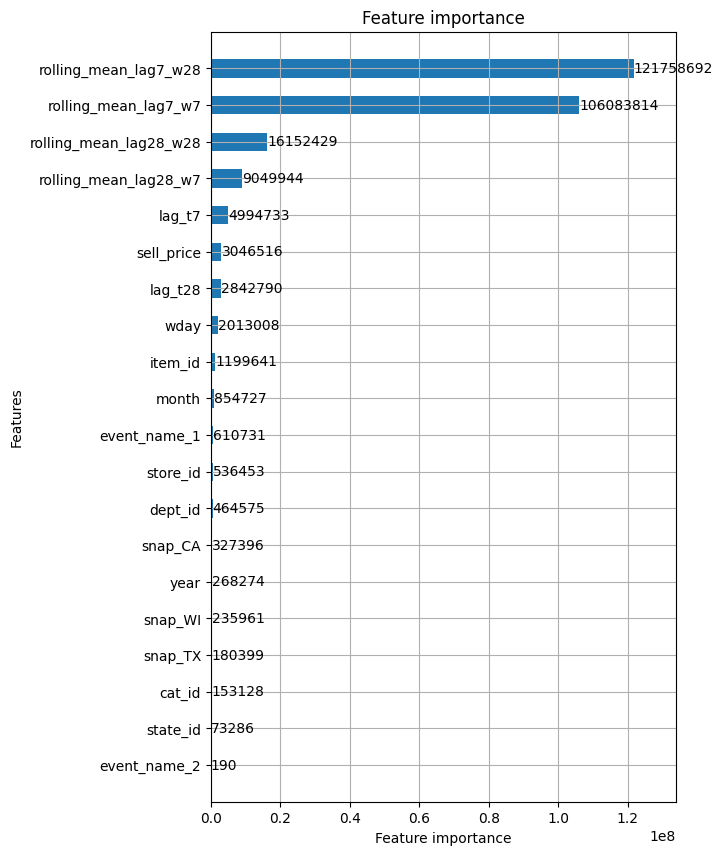

In [28]:
import gc

# Force garbage collection
gc.collect()



train, valid, test, x = prep_train(df)
fit = fit_model(train, valid)

In [29]:
pred = pred_all(fit, test, x)
pred_to_csv(pred, cols=sample_submission.columns, file="submission.csv")

ValueError: cannot reindex from a duplicate axis